
# RQ20 — Where does degradation occur along the 90→70→50→30 trajectory?

## Scientific question

**Do supervised and positive–unlabeled prediction systems degrade smoothly as sequence constraints become stricter, or is the loss concentrated in an early, middle, or late transition?**

RQ20 consolidates stepwise information already present in RQ2, RQ3, and PU-RQ13. It does **not** train models, regenerate predictions, or bootstrap uncertainty.

For both redundancy control (`R`) and homology separation (`S`), the ordered transitions are:

- `90→70` — early transition
- `70→50` — middle transition
- `50→30` — late transition

### Main objectives

1. quantify the three consecutive stepwise changes for supervised MCC;
2. quantify the same three transitions for PU U95 positive recovery;
3. identify which transition carries the largest degradation for every trajectory;
4. distinguish stable, monotonic/degradation-timed, improving, and non-monotonic response shapes;
5. determine whether a universal breakpoint exists;
6. compare breakpoint timing across biological tasks, representations, learners, PU tasks, and PU methods;
7. distinguish a large endpoint loss from a locally complex trajectory.



## Interpretation contract

- Lower `R` and lower `S` are more stringent.
- Supervised primary metric: **MCC**.
- PU primary metric: **fraction of labeled positives at or above the U95 threshold**, using the canonical inclusive `>=` definition from RQ12/RQ13.
- R/S native test populations can change across threshold levels. Therefore stepwise deltas are **native-test generalization contrasts**, not paired per-protein causal effects.
- Common-test interpretation remains RQ18.
- Statistical uncertainty remains RQ19.
- RQ20 is about **trajectory shape and breakpoint timing**, not about declaring a threshold universally optimal.

### Shape tolerances

To remain consistent with earlier analyses:

- supervised MCC monotonic/stability tolerance: **0.005**, matching RQ2;
- PU U95 practical-tie tolerance: **0.02**, matching RQ13.

These are descriptive tolerances, not statistical equivalence margins.

### Trajectory categories

For each four-point trajectory:

- `stable` — all three adjacent changes are within tolerance;
- `non_monotonic` — there is at least one meaningful increase and one meaningful decrease;
- `improving` — meaningful increase(s) without a meaningful decrease;
- `early_degradation` — degradative trajectory whose largest negative step is `90→70`;
- `mid_degradation` — largest negative step is `70→50`;
- `late_degradation` — largest negative step is `50→30`.

The output also retains exact step magnitudes, net endpoint change, total absolute movement, and degradation concentration, so the categorical label never replaces the underlying data.


In [1]:

from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 400)
pd.set_option("display.width", 260)
pd.set_option("display.max_rows", 400)

LEVELS = [90, 70, 50, 30]
STEP_PAIRS = [(90, 70), (70, 50), (50, 30)]
STEP_TIMING = {
    (90, 70): "early",
    (70, 50): "mid",
    (50, 30): "late",
}

SUP_METRIC = "mcc"
PU_METRIC = "fraction_P_above_U95"

SUP_TOL = 0.005
PU_TOL = 0.02

TASK_ORDER = [
    "global_easy",
    "global_hard",
    "global_mixed",
    "subtype_endolysin",
    "subtype_depolymerase",
    "subtype_val",
    "multiclass_clean",
]

REP_ORDER = [
    "roxy_48",
    "onehot_1024",
    "esm2_t6_8m",
    "esm2_t30_150m",
]

ALG_ORDER = ["KNN", "LR", "MLP", "RF", "XGB"]
PU_METHOD_ORDER = ["naive", "baggingpu", "elkan_noto"]


def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (
            (candidate / "results/analysis_supervised/stage12a").is_dir()
            and (candidate / "results/analysis_supervised/stage12b").is_dir()
            and (candidate / "results/analysis_pu/notebook_cache").is_dir()
        ):
            return candidate
    raise FileNotFoundError(
        "Could not locate a project root containing supervised Stage12A/12B "
        "and results/analysis_pu/notebook_cache."
    )


ROOT = find_project_root()

SUP_STAGE12A = ROOT / "results/analysis_supervised/stage12a"
SUP_STAGE12B = ROOT / "results/analysis_supervised/stage12b"
SUP_CACHE = ROOT / "results/analysis_supervised/notebook_cache"

PU_CACHE = ROOT / "results/analysis_pu/notebook_cache"

RQ20_OUT = SUP_CACHE / "rq20_stepwise_regimes"
FIG_DIR = RQ20_OUT / "figures"
RQ20_OUT.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)
print("RQ20_OUT:", RQ20_OUT)
print("No training, prediction regeneration, or bootstrap is performed.")


ROOT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass
RQ20_OUT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq20_stepwise_regimes
No training, prediction regeneration, or bootstrap is performed.


## 1. Load and validate canonical supervised inputs

In [2]:

master = pd.read_csv(
    SUP_STAGE12A / "supervised_master_results.tsv",
    sep="\t",
    low_memory=False,
)

r_deltas = pd.read_csv(
    SUP_STAGE12B / "rs_redundancy_deltas_fixed_S.tsv",
    sep="\t",
    low_memory=False,
)

s_delta_candidates = [
    SUP_STAGE12B / "rs_split_deltas_fixed_R.tsv",
    SUP_STAGE12B / "rs_homology_deltas_fixed_R.tsv",
    SUP_STAGE12B / "rs_separation_deltas_fixed_R.tsv",
    SUP_STAGE12B / "s_deltas_fixed_R.tsv",
]
s_delta_path = next((p for p in s_delta_candidates if p.is_file()), None)
if s_delta_path is None:
    raise FileNotFoundError(
        "Could not locate fixed-R S-delta table. Available Stage12B TSVs:\n"
        + "\n".join(sorted(p.name for p in SUP_STAGE12B.glob("*.tsv")))
    )

s_deltas = pd.read_csv(s_delta_path, sep="\t", low_memory=False)

required_master = {
    "task", "R", "S", "representation", "algorithm", SUP_METRIC
}
missing = required_master - set(master.columns)
if missing:
    raise KeyError(f"Supervised master missing: {sorted(missing)}")

for col in ["R", "S", SUP_METRIC]:
    master[col] = pd.to_numeric(master[col], errors="raise")

master["R"] = master["R"].astype(int)
master["S"] = master["S"].astype(int)

assert len(master) == 2240, f"Expected 2240 supervised families, found {len(master)}"

coverage = (
    master.groupby(["task", "representation", "algorithm"])
    .size()
)
assert len(coverage) == 140
assert coverage.eq(16).all()

print("Supervised rows:", len(master))
print("Complete supervised R×S surfaces:", len(coverage))
print("S delta source:", s_delta_path.name)
print("SUPERVISED_PREFLIGHT_OK")


Supervised rows: 2240
Complete supervised R×S surfaces: 140
S delta source: rs_split_deltas_fixed_R.tsv
SUPERVISED_PREFLIGHT_OK


## 2. Extract only consecutive supervised steps

In [3]:

rd = r_deltas[r_deltas["metric"].eq(SUP_METRIC)].copy()

# Standardize S-delta schema.
if {"S_from", "S_to"} <= set(s_deltas.columns):
    S_FROM, S_TO = "S_from", "S_to"
elif {"threshold_from", "threshold_to"} <= set(s_deltas.columns):
    S_FROM, S_TO = "threshold_from", "threshold_to"
else:
    raise KeyError(
        "Could not identify S_from/S_to or threshold_from/threshold_to."
    )

R_FIXED = "R_fixed" if "R_fixed" in s_deltas.columns else "R"
sd = s_deltas[s_deltas["metric"].eq(SUP_METRIC)].copy()

sup_R_steps = rd[
    rd.apply(
        lambda x: (int(x["R_from"]), int(x["R_to"])) in STEP_PAIRS,
        axis=1,
    )
].copy()

sup_R_steps["axis"] = "R"
sup_R_steps["condition_fixed"] = sup_R_steps["S_fixed"].astype(int)
sup_R_steps["from_level"] = sup_R_steps["R_from"].astype(int)
sup_R_steps["to_level"] = sup_R_steps["R_to"].astype(int)
sup_R_steps["timing"] = [
    STEP_TIMING[(a, b)]
    for a, b in zip(sup_R_steps["from_level"], sup_R_steps["to_level"])
]
sup_R_steps["step"] = (
    "R" + sup_R_steps["from_level"].astype(str)
    + "→R" + sup_R_steps["to_level"].astype(str)
)
sup_R_steps["metric"] = SUP_METRIC

sup_S_steps = sd[
    sd.apply(
        lambda x: (int(x[S_FROM]), int(x[S_TO])) in STEP_PAIRS,
        axis=1,
    )
].copy()

sup_S_steps["axis"] = "S"
sup_S_steps["condition_fixed"] = sup_S_steps[R_FIXED].astype(int)
sup_S_steps["from_level"] = sup_S_steps[S_FROM].astype(int)
sup_S_steps["to_level"] = sup_S_steps[S_TO].astype(int)
sup_S_steps["timing"] = [
    STEP_TIMING[(a, b)]
    for a, b in zip(sup_S_steps["from_level"], sup_S_steps["to_level"])
]
sup_S_steps["step"] = (
    "S" + sup_S_steps["from_level"].astype(str)
    + "→S" + sup_S_steps["to_level"].astype(str)
)
sup_S_steps["metric"] = SUP_METRIC

sup_step_cols = [
    "task", "representation", "algorithm",
    "axis", "condition_fixed", "from_level", "to_level",
    "timing", "step", "metric", "value_from", "value_to", "delta",
]

sup_steps = pd.concat(
    [
        sup_R_steps[sup_step_cols],
        sup_S_steps[sup_step_cols],
    ],
    ignore_index=True,
)

sup_steps["abs_delta"] = sup_steps["delta"].abs()
sup_steps["loss"] = (-sup_steps["delta"]).clip(lower=0)

# 560 R trajectories + 560 S trajectories, each with 3 steps.
assert len(sup_R_steps) == 560 * 3
assert len(sup_S_steps) == 560 * 3
assert len(sup_steps) == 3360

print("Supervised consecutive R steps:", len(sup_R_steps))
print("Supervised consecutive S steps:", len(sup_S_steps))
display(
    sup_steps.groupby(["axis", "timing"])["delta"]
    .agg(n="size", median="median", mean="mean",
         median_abs=lambda x: x.abs().median(),
         fraction_negative=lambda x: (x < 0).mean())
    .reset_index()
)


Supervised consecutive R steps: 1680
Supervised consecutive S steps: 1680


,axis,timing,n,median,mean,median_abs,fraction_negative
0,R,early,560,-0.022014,-0.018252,0.034586,0.735714
1,R,late,560,-0.022173,-0.013584,0.031941,0.685714
2,R,mid,560,-0.023619,-0.041335,0.030822,0.725000
3,S,early,560,-0.001793,-0.006496,0.012320,0.535714
4,S,late,560,-0.008059,-0.016838,0.020756,0.633929
5,S,mid,560,-0.005392,-0.015360,0.016938,0.591071


## 3. Build supervised four-point trajectories and timing classes

In [4]:

def classify_trajectory(values, tol):
    values = np.asarray(values, dtype=float)
    if values.shape != (4,) or not np.isfinite(values).all():
        raise ValueError(f"Expected four finite trajectory values, got {values}")

    diffs = np.diff(values)
    neg = diffs < -tol
    pos = diffs > tol

    net = float(values[-1] - values[0])
    total_abs = float(np.abs(diffs).sum())
    total_loss = float(np.clip(-diffs, 0, None).sum())

    movement_idx = int(np.argmax(np.abs(diffs)))
    dominant_movement_timing = STEP_TIMING[STEP_PAIRS[movement_idx]]
    dominant_movement_delta = float(diffs[movement_idx])

    degradation_idx = int(np.argmin(diffs))
    dominant_degradation_timing = (
        STEP_TIMING[STEP_PAIRS[degradation_idx]] if neg.any() else "none"
    )
    dominant_degradation_delta = (
        float(diffs[degradation_idx]) if neg.any() else 0.0
    )

    if np.all(np.abs(diffs) <= tol):
        regime = "stable"
    elif neg.any() and pos.any():
        regime = "non_monotonic"
    elif pos.any() and not neg.any():
        regime = "improving"
    else:
        # One or more meaningful degradative steps, no meaningful increase.
        regime = f"{dominant_degradation_timing}_degradation"

    degradation_concentration = (
        abs(dominant_degradation_delta) / total_loss
        if total_loss > 0 else np.nan
    )

    return {
        "v90": float(values[0]),
        "v70": float(values[1]),
        "v50": float(values[2]),
        "v30": float(values[3]),
        "delta_90_70": float(diffs[0]),
        "delta_70_50": float(diffs[1]),
        "delta_50_30": float(diffs[2]),
        "net_90_30": net,
        "total_abs_movement": total_abs,
        "total_degradation": total_loss,
        "dominant_movement_timing": dominant_movement_timing,
        "dominant_movement_delta": dominant_movement_delta,
        "dominant_degradation_timing": dominant_degradation_timing,
        "dominant_degradation_delta": dominant_degradation_delta,
        "degradation_concentration": degradation_concentration,
        "regime": regime,
    }


sup_traj_rows = []

# R trajectories at fixed S.
for keys, grp in master.groupby(
    ["task", "representation", "algorithm", "S"],
    sort=False,
):
    task, rep, alg, s = keys
    vals = (
        grp.set_index("R")
        .reindex(LEVELS)[SUP_METRIC]
        .astype(float)
        .to_numpy()
    )
    row = {
        "domain": "supervised",
        "metric": SUP_METRIC,
        "axis": "R",
        "task": task,
        "representation": rep,
        "algorithm": alg,
        "method": pd.NA,
        "condition_fixed": int(s),
        "tolerance": SUP_TOL,
    }
    row.update(classify_trajectory(vals, SUP_TOL))
    sup_traj_rows.append(row)

# S trajectories at fixed R.
for keys, grp in master.groupby(
    ["task", "representation", "algorithm", "R"],
    sort=False,
):
    task, rep, alg, r = keys
    vals = (
        grp.set_index("S")
        .reindex(LEVELS)[SUP_METRIC]
        .astype(float)
        .to_numpy()
    )
    row = {
        "domain": "supervised",
        "metric": SUP_METRIC,
        "axis": "S",
        "task": task,
        "representation": rep,
        "algorithm": alg,
        "method": pd.NA,
        "condition_fixed": int(r),
        "tolerance": SUP_TOL,
    }
    row.update(classify_trajectory(vals, SUP_TOL))
    sup_traj_rows.append(row)

sup_trajectories = pd.DataFrame(sup_traj_rows)
sup_trajectories["dominant_timing"] = sup_trajectories["dominant_degradation_timing"]
sup_trajectories["dominant_step_delta"] = sup_trajectories["dominant_degradation_delta"]

assert len(sup_trajectories) == 1120
assert sup_trajectories.groupby("axis").size().to_dict() == {"R": 560, "S": 560}

print("Supervised trajectories:", len(sup_trajectories))
display(
    pd.crosstab(
        sup_trajectories["axis"],
        sup_trajectories["regime"],
        normalize="index",
    )
)


Supervised trajectories: 1120


regime,early_degradation,improving,late_degradation,mid_degradation,non_monotonic,stable
axis,,,,,,
R,0.132143,0.041071,0.246429,0.125000,0.444643,0.010714
S,0.069643,0.055357,0.098214,0.098214,0.633929,0.044643



## 4. Load canonical PU-RQ13 stepwise caches

RQ20 consumes the exact RQ13 exports:

- `rq13_pu_R_stepwise_effects.tsv`
- `rq13_pu_S_stepwise_effects.tsv`

and the canonical RQ12 native diagnostic table only to reconstruct four-point trajectories for classification. No PU scores are regenerated.


In [5]:

PU_R_STEP_PATH = PU_CACHE / "rq13_pu_R_stepwise_effects.tsv"
PU_S_STEP_PATH = PU_CACHE / "rq13_pu_S_stepwise_effects.tsv"
PU_NATIVE_PATH = PU_CACHE / "rq12_pu_native_score_diagnostics.tsv"

for path in [PU_R_STEP_PATH, PU_S_STEP_PATH, PU_NATIVE_PATH]:
    if not path.is_file():
        raise FileNotFoundError(
            f"Required completed PU cache missing: {path}. "
            "RQ12/RQ13 must be executed before RQ20."
        )

pu_R_raw = pd.read_csv(PU_R_STEP_PATH, sep="\t", low_memory=False)
pu_S_raw = pd.read_csv(PU_S_STEP_PATH, sep="\t", low_memory=False)
pu_native = pd.read_csv(PU_NATIVE_PATH, sep="\t", low_memory=False)

required_pu = {
    "task", "R", "S", "representation", "method", "algorithm", PU_METRIC
}
missing = required_pu - set(pu_native.columns)
if missing:
    raise KeyError(f"PU native diagnostics missing: {sorted(missing)}")

for col in ["R", "S", PU_METRIC]:
    pu_native[col] = pd.to_numeric(pu_native[col], errors="raise")

pu_native["R"] = pu_native["R"].astype(int)
pu_native["S"] = pu_native["S"].astype(int)

assert len(pu_native) == 768
pu_surface_coverage = (
    pu_native.groupby(["task", "representation", "method", "algorithm"])
    .size()
)
assert len(pu_surface_coverage) == 48
assert pu_surface_coverage.eq(16).all()

print("PU rows:", len(pu_native))
print("Complete PU surfaces:", len(pu_surface_coverage))
print("RQ13 R-step rows:", len(pu_R_raw))
print("RQ13 S-step rows:", len(pu_S_raw))
print("PU_PREFLIGHT_OK")


PU rows: 768
Complete PU surfaces: 48
RQ13 R-step rows: 576
RQ13 S-step rows: 576
PU_PREFLIGHT_OK


## 5. Standardize PU stepwise effects

In [6]:

def standardize_pu_steps(df, axis):
    x = df.copy()

    if "metric" in x.columns:
        x = x[x["metric"].eq(PU_METRIC)].copy()

    if axis == "R":
        fixed_col = "S_fixed"
        from_col, to_col = "R_from", "R_to"
    else:
        fixed_col = "R_fixed"
        from_col, to_col = "S_from", "S_to"

    required = {
        "task", "representation", "method", "algorithm",
        fixed_col, from_col, to_col, "delta",
    }
    missing = required - set(x.columns)
    if missing:
        raise KeyError(f"PU {axis} step cache missing: {sorted(missing)}")

    x = x[
        x.apply(
            lambda r: (int(r[from_col]), int(r[to_col])) in STEP_PAIRS,
            axis=1,
        )
    ].copy()

    x["axis"] = axis
    x["condition_fixed"] = x[fixed_col].astype(int)
    x["from_level"] = x[from_col].astype(int)
    x["to_level"] = x[to_col].astype(int)
    x["timing"] = [
        STEP_TIMING[(a, b)]
        for a, b in zip(x["from_level"], x["to_level"])
    ]
    x["step"] = (
        axis + x["from_level"].astype(str)
        + "→" + axis + x["to_level"].astype(str)
    )
    x["metric"] = PU_METRIC
    x["abs_delta"] = x["delta"].abs()
    x["loss"] = (-x["delta"]).clip(lower=0)

    return x[
        [
            "task", "representation", "method", "algorithm",
            "axis", "condition_fixed", "from_level", "to_level",
            "timing", "step", "metric", "delta", "abs_delta", "loss",
        ]
    ]


pu_R_steps = standardize_pu_steps(pu_R_raw, "R")
pu_S_steps = standardize_pu_steps(pu_S_raw, "S")
pu_steps = pd.concat([pu_R_steps, pu_S_steps], ignore_index=True)

assert len(pu_R_steps) == 192 * 3
assert len(pu_S_steps) == 192 * 3
assert len(pu_steps) == 1152

print("PU consecutive R steps:", len(pu_R_steps))
print("PU consecutive S steps:", len(pu_S_steps))
display(
    pu_steps.groupby(["axis", "timing"])["delta"]
    .agg(
        n="size",
        median="median",
        mean="mean",
        median_abs=lambda x: x.abs().median(),
        fraction_negative=lambda x: (x < 0).mean(),
    )
    .reset_index()
)


PU consecutive R steps: 576
PU consecutive S steps: 576


,axis,timing,n,median,mean,median_abs,fraction_negative
0,R,early,192,-0.025493,-0.031338,0.025493,0.921875
1,R,late,192,-0.018112,-0.017197,0.024440,0.765625
2,R,mid,192,-0.028280,-0.025795,0.030531,0.864583
3,S,early,192,0.001470,-0.000057,0.015539,0.494792
4,S,late,192,-0.009313,-0.011761,0.015147,0.770833
5,S,mid,192,-0.003032,-0.002071,0.012506,0.578125


## 6. Build PU trajectory timing classes

In [7]:

pu_traj_rows = []

for keys, grp in pu_native.groupby(
    ["task", "representation", "method", "algorithm", "S"],
    sort=False,
):
    task, rep, method, alg, s = keys
    vals = (
        grp.set_index("R")
        .reindex(LEVELS)[PU_METRIC]
        .astype(float)
        .to_numpy()
    )
    row = {
        "domain": "PU",
        "metric": PU_METRIC,
        "axis": "R",
        "task": task,
        "representation": rep,
        "algorithm": alg,
        "method": method,
        "condition_fixed": int(s),
        "tolerance": PU_TOL,
    }
    row.update(classify_trajectory(vals, PU_TOL))
    pu_traj_rows.append(row)

for keys, grp in pu_native.groupby(
    ["task", "representation", "method", "algorithm", "R"],
    sort=False,
):
    task, rep, method, alg, r = keys
    vals = (
        grp.set_index("S")
        .reindex(LEVELS)[PU_METRIC]
        .astype(float)
        .to_numpy()
    )
    row = {
        "domain": "PU",
        "metric": PU_METRIC,
        "axis": "S",
        "task": task,
        "representation": rep,
        "algorithm": alg,
        "method": method,
        "condition_fixed": int(r),
        "tolerance": PU_TOL,
    }
    row.update(classify_trajectory(vals, PU_TOL))
    pu_traj_rows.append(row)

pu_trajectories = pd.DataFrame(pu_traj_rows)
pu_trajectories["dominant_timing"] = pu_trajectories["dominant_degradation_timing"]
pu_trajectories["dominant_step_delta"] = pu_trajectories["dominant_degradation_delta"]

assert len(pu_trajectories) == 384
assert pu_trajectories.groupby("axis").size().to_dict() == {"R": 192, "S": 192}

print("PU trajectories:", len(pu_trajectories))
display(
    pd.crosstab(
        pu_trajectories["axis"],
        pu_trajectories["regime"],
        normalize="index",
    )
)


PU trajectories: 384


regime,early_degradation,improving,late_degradation,mid_degradation,non_monotonic,stable
axis,,,,,,
R,0.187500,0.026042,0.265625,0.317708,0.145833,0.057292
S,0.088542,0.072917,0.130208,0.062500,0.307292,0.338542


## 7. Canonical global stepwise summaries

In [8]:

sup_step_summary = (
    sup_steps.groupby(["axis", "timing", "step"], as_index=False)
    .agg(
        n=("delta", "size"),
        mean_delta=("delta", "mean"),
        median_delta=("delta", "median"),
        q25=("delta", lambda x: x.quantile(0.25)),
        q75=("delta", lambda x: x.quantile(0.75)),
        median_abs_delta=("delta", lambda x: x.abs().median()),
        fraction_negative=("delta", lambda x: (x < 0).mean()),
        fraction_positive=("delta", lambda x: (x > 0).mean()),
        fraction_within_tol=("delta", lambda x: (x.abs() <= SUP_TOL).mean()),
    )
)

pu_step_summary = (
    pu_steps.groupby(["axis", "timing", "step"], as_index=False)
    .agg(
        n=("delta", "size"),
        mean_delta=("delta", "mean"),
        median_delta=("delta", "median"),
        q25=("delta", lambda x: x.quantile(0.25)),
        q75=("delta", lambda x: x.quantile(0.75)),
        median_abs_delta=("delta", lambda x: x.abs().median()),
        fraction_negative=("delta", lambda x: (x < 0).mean()),
        fraction_positive=("delta", lambda x: (x > 0).mean()),
        fraction_within_tol=("delta", lambda x: (x.abs() <= PU_TOL).mean()),
    )
)

print("Supervised MCC")
display(sup_step_summary)

print("PU U95 recovery")
display(pu_step_summary)


Supervised MCC


,axis,timing,step,n,mean_delta,median_delta,q25,q75,median_abs_delta,fraction_negative,fraction_positive,fraction_within_tol
0,R,early,R90→R70,560,-0.018252,-0.022014,-0.052118,0.000000,0.034586,0.735714,0.248214,0.083929
1,R,late,R50→R30,560,-0.013584,-0.022173,-0.043332,0.006524,0.031941,0.685714,0.282143,0.083929
2,R,mid,R70→R50,560,-0.041335,-0.023619,-0.049133,0.000000,0.030822,0.725000,0.248214,0.126786
3,S,early,S90→S70,560,-0.006496,-0.001793,-0.016374,0.008816,0.012320,0.535714,0.403571,0.244643
4,S,late,S50→S30,560,-0.016838,-0.008059,-0.031369,0.008180,0.020756,0.633929,0.335714,0.167857
5,S,mid,S70→S50,560,-0.015360,-0.005392,-0.030997,0.007078,0.016938,0.591071,0.380357,0.214286


PU U95 recovery


,axis,timing,step,n,mean_delta,median_delta,q25,q75,median_abs_delta,fraction_negative,fraction_positive,fraction_within_tol
0,R,early,R90→R70,192,-0.031338,-0.025493,-0.041982,-0.013408,0.025493,0.921875,0.078125,0.406250
1,R,late,R50→R30,192,-0.017197,-0.018112,-0.035829,-0.001320,0.024440,0.765625,0.234375,0.411458
2,R,mid,R70→R50,192,-0.025795,-0.028280,-0.041014,-0.007759,0.030531,0.864583,0.135417,0.364583
3,S,early,S90→S70,192,-0.000057,0.001470,-0.012561,0.017169,0.015539,0.494792,0.505208,0.630208
4,S,late,S50→S30,192,-0.011761,-0.009313,-0.025160,-0.000545,0.015147,0.770833,0.229167,0.604167
5,S,mid,S70→S50,192,-0.002071,-0.003032,-0.013358,0.010653,0.012506,0.578125,0.421875,0.677083



## 8. Is there a universal breakpoint?

For each trajectory, the **dominant degradative step** is the adjacent transition with the most negative delta.

For trajectories classified as `stable`, `non_monotonic`, or `improving`, the shape label is retained separately. We do not force those curves into an early/mid/late degradation narrative.

A universal breakpoint would require strong concentration of degradative trajectories in the same timing interval across tasks/model families. RQ20 reports the observed proportions rather than imposing a significance threshold for “universality”.


In [9]:

all_trajectories = pd.concat(
    [sup_trajectories, pu_trajectories],
    ignore_index=True,
)

def regime_distribution(df, group_cols):
    out = (
        df.groupby(group_cols + ["regime"], dropna=False)
        .size()
        .rename("n")
        .reset_index()
    )
    out["fraction"] = (
        out["n"]
        / out.groupby(group_cols)["n"].transform("sum")
    )
    return out

sup_regime_global = regime_distribution(sup_trajectories, ["axis"])
pu_regime_global = regime_distribution(pu_trajectories, ["axis"])

print("Supervised regime fractions")
display(sup_regime_global)

print("PU regime fractions")
display(pu_regime_global)

sup_degradative = sup_trajectories[
    sup_trajectories["regime"].isin(
        ["early_degradation", "mid_degradation", "late_degradation"]
    )
].copy()

pu_degradative = pu_trajectories[
    pu_trajectories["regime"].isin(
        ["early_degradation", "mid_degradation", "late_degradation"]
    )
].copy()

sup_breakpoint = (
    sup_degradative.groupby(["axis", "dominant_timing"])
    .size()
    .rename("n")
    .reset_index()
)
sup_breakpoint["fraction_within_axis_degradative"] = (
    sup_breakpoint["n"]
    / sup_breakpoint.groupby("axis")["n"].transform("sum")
)

pu_breakpoint = (
    pu_degradative.groupby(["axis", "dominant_timing"])
    .size()
    .rename("n")
    .reset_index()
)
pu_breakpoint["fraction_within_axis_degradative"] = (
    pu_breakpoint["n"]
    / pu_breakpoint.groupby("axis")["n"].transform("sum")
)

print("Dominant supervised degradation timing")
display(sup_breakpoint)

print("Dominant PU degradation timing")
display(pu_breakpoint)


Supervised regime fractions


,axis,regime,n,fraction
0,R,early_degradation,74,0.132143
1,R,improving,23,0.041071
2,R,late_degradation,138,0.246429
3,R,mid_degradation,70,0.125000
4,R,non_monotonic,249,0.444643
5,R,stable,6,0.010714
6,S,early_degradation,39,0.069643
7,S,improving,31,0.055357
8,S,late_degradation,55,0.098214
9,S,mid_degradation,55,0.098214


PU regime fractions


,axis,regime,n,fraction
0,R,early_degradation,36,0.187500
1,R,improving,5,0.026042
2,R,late_degradation,51,0.265625
3,R,mid_degradation,61,0.317708
4,R,non_monotonic,28,0.145833
5,R,stable,11,0.057292
6,S,early_degradation,17,0.088542
7,S,improving,14,0.072917
8,S,late_degradation,25,0.130208
9,S,mid_degradation,12,0.062500


Dominant supervised degradation timing


,axis,dominant_timing,n,fraction_within_axis_degradative
0,R,early,74,0.262411
1,R,late,138,0.489362
2,R,mid,70,0.248227
3,S,early,39,0.261745
4,S,late,55,0.369128
5,S,mid,55,0.369128


Dominant PU degradation timing


,axis,dominant_timing,n,fraction_within_axis_degradative
0,R,early,36,0.243243
1,R,late,51,0.344595
2,R,mid,61,0.412162
3,S,early,17,0.314815
4,S,late,25,0.462963
5,S,mid,12,0.222222


## 9. Task-specific trajectory regimes

In [10]:

sup_task_regimes = regime_distribution(
    sup_trajectories,
    ["axis", "task"],
)

pu_task_regimes = regime_distribution(
    pu_trajectories,
    ["axis", "task"],
)

display(
    sup_task_regimes.sort_values(
        ["axis", "task", "fraction"],
        ascending=[True, True, False],
    )
)

display(
    pu_task_regimes.sort_values(
        ["axis", "task", "fraction"],
        ascending=[True, True, False],
    )
)


,axis,task,regime,n,fraction
1,R,global_easy,late_degradation,32,0.4000
2,R,global_easy,mid_degradation,20,0.2500
3,R,global_easy,non_monotonic,19,0.2375
0,R,global_easy,early_degradation,9,0.1125
5,R,global_hard,late_degradation,31,0.3875
7,R,global_hard,non_monotonic,25,0.3125
4,R,global_hard,early_degradation,16,0.2000
6,R,global_hard,mid_degradation,8,0.1000
9,R,global_mixed,late_degradation,28,0.3500
8,R,global_mixed,early_degradation,21,0.2625


,axis,task,regime,n,fraction
2,R,pu_broad,late_degradation,32,0.333333
3,R,pu_broad,mid_degradation,23,0.239583
0,R,pu_broad,early_degradation,21,0.218750
4,R,pu_broad,non_monotonic,13,0.135417
5,R,pu_broad,stable,5,0.052083
1,R,pu_broad,improving,2,0.020833
9,R,pu_conservative,mid_degradation,38,0.395833
8,R,pu_conservative,late_degradation,19,0.197917
6,R,pu_conservative,early_degradation,15,0.156250
10,R,pu_conservative,non_monotonic,15,0.156250


## 10. Representation, learner, and PU-method modulation of timing

In [11]:

sup_rep_regimes = regime_distribution(
    sup_trajectories,
    ["axis", "representation"],
)

sup_alg_regimes = regime_distribution(
    sup_trajectories,
    ["axis", "algorithm"],
)

pu_rep_regimes = regime_distribution(
    pu_trajectories,
    ["axis", "representation"],
)

pu_method_regimes = regime_distribution(
    pu_trajectories,
    ["axis", "method"],
)

print("Supervised representation × regime")
display(sup_rep_regimes)

print("Supervised learner × regime")
display(sup_alg_regimes)

print("PU representation × regime")
display(pu_rep_regimes)

print("PU method × regime")
display(pu_method_regimes)


Supervised representation × regime


,axis,representation,regime,n,fraction
0,R,esm2_t30_150m,early_degradation,2,0.014286
1,R,esm2_t30_150m,improving,2,0.014286
2,R,esm2_t30_150m,late_degradation,69,0.492857
3,R,esm2_t30_150m,mid_degradation,16,0.114286
4,R,esm2_t30_150m,non_monotonic,51,0.364286
5,R,esm2_t6_8m,early_degradation,16,0.114286
6,R,esm2_t6_8m,improving,8,0.057143
7,R,esm2_t6_8m,late_degradation,35,0.250000
8,R,esm2_t6_8m,mid_degradation,20,0.142857
9,R,esm2_t6_8m,non_monotonic,61,0.435714


Supervised learner × regime


,axis,algorithm,regime,n,fraction
0,R,KNN,early_degradation,13,0.116071
1,R,KNN,improving,3,0.026786
2,R,KNN,late_degradation,37,0.330357
3,R,KNN,mid_degradation,18,0.160714
4,R,KNN,non_monotonic,41,0.366071
5,R,LR,early_degradation,18,0.160714
6,R,LR,improving,7,0.062500
7,R,LR,late_degradation,20,0.178571
8,R,LR,mid_degradation,14,0.125000
9,R,LR,non_monotonic,52,0.464286


PU representation × regime


,axis,representation,regime,n,fraction
0,R,esm2_t30_150m,early_degradation,2,0.041667
1,R,esm2_t30_150m,late_degradation,27,0.562500
2,R,esm2_t30_150m,mid_degradation,18,0.375000
3,R,esm2_t30_150m,stable,1,0.020833
4,R,esm2_t6_8m,early_degradation,5,0.104167
5,R,esm2_t6_8m,late_degradation,16,0.333333
6,R,esm2_t6_8m,mid_degradation,25,0.520833
7,R,esm2_t6_8m,stable,2,0.041667
8,R,onehot_1024,early_degradation,21,0.437500
9,R,onehot_1024,late_degradation,2,0.041667


PU method × regime


,axis,method,regime,n,fraction
0,R,baggingpu,early_degradation,11,0.171875
1,R,baggingpu,improving,2,0.031250
2,R,baggingpu,late_degradation,17,0.265625
3,R,baggingpu,mid_degradation,17,0.265625
4,R,baggingpu,non_monotonic,13,0.203125
5,R,baggingpu,stable,4,0.062500
6,R,elkan_noto,early_degradation,13,0.203125
7,R,elkan_noto,improving,1,0.015625
8,R,elkan_noto,late_degradation,18,0.281250
9,R,elkan_noto,mid_degradation,22,0.343750


## 11. Endpoint loss versus local trajectory complexity

In [12]:

trajectory_complexity_summary = (
    all_trajectories.groupby(["domain", "axis", "regime"], as_index=False)
    .agg(
        n=("net_90_30", "size"),
        median_net_90_30=("net_90_30", "median"),
        median_total_abs_movement=("total_abs_movement", "median"),
        median_total_degradation=("total_degradation", "median"),
        median_degradation_concentration=("degradation_concentration", "median"),
    )
)

display(trajectory_complexity_summary)

# High local movement with small endpoint change is a useful diagnostic of
# non-monotonic / compensating trajectories.
all_trajectories["movement_to_net_ratio"] = (
    all_trajectories["total_abs_movement"]
    / all_trajectories["net_90_30"].abs().replace(0, np.nan)
)

display(
    all_trajectories.groupby(["domain", "axis"])["movement_to_net_ratio"]
    .agg(["median", "mean"])
)


,domain,axis,regime,n,median_net_90_30,median_total_abs_movement,median_total_degradation,median_degradation_concentration
0,PU,R,early_degradation,36,-0.099619,0.107142,0.101798,0.533366
1,PU,R,improving,5,-0.000341,0.053340,0.026841,0.000000
2,PU,R,late_degradation,51,-0.082775,0.082775,0.082775,0.586250
3,PU,R,mid_degradation,61,-0.083266,0.083266,0.083266,0.557727
4,PU,R,non_monotonic,28,-0.028642,0.105836,0.066141,0.720660
5,PU,R,stable,11,-0.010026,0.025995,0.017686,0.000000
6,PU,S,early_degradation,17,-0.057713,0.060923,0.057713,0.632330
7,PU,S,improving,14,0.010702,0.050532,0.020464,0.000000
8,PU,S,late_degradation,25,-0.028721,0.048565,0.035745,0.763527
9,PU,S,mid_degradation,12,-0.037701,0.058304,0.046578,0.686630


median         mean
domain     axis                       
PU         R     1.000000     4.399279
           S     3.301533    12.603172
supervised R     1.024570     4.432000
           S     1.923297  2570.347309

## 12. Figures

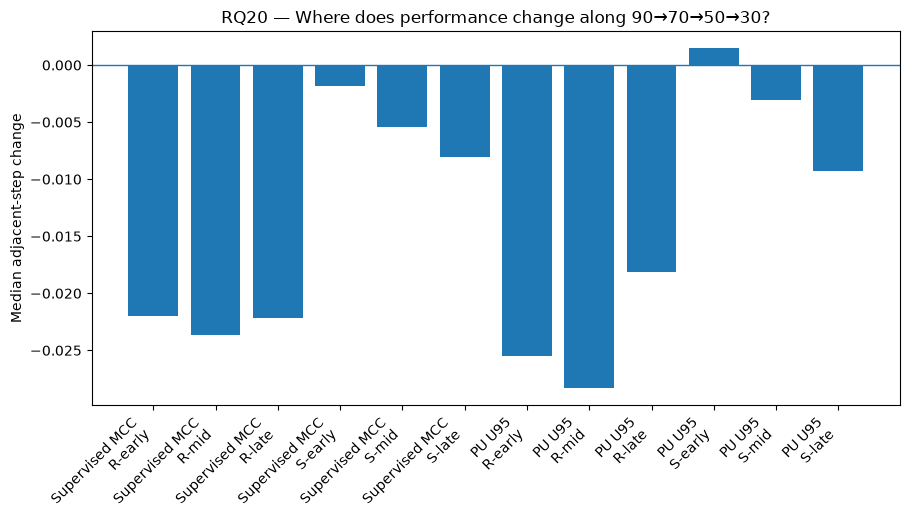

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq20_stepwise_regimes/figures/rq20_global_stepwise_deltas.png


In [13]:

# Figure 1 — global supervised and PU stepwise deltas.
fig, ax = plt.subplots(figsize=(9.2, 5.4))

plot_rows = []
for domain, table in [("Supervised MCC", sup_step_summary), ("PU U95", pu_step_summary)]:
    for _, row in table.iterrows():
        plot_rows.append({
            "domain": domain,
            "axis": row["axis"],
            "timing": row["timing"],
            "median_delta": row["median_delta"],
        })

plot_df = pd.DataFrame(plot_rows)

x_labels = []
x_vals = []
y_vals = []

order = [
    ("Supervised MCC", "R", "early"),
    ("Supervised MCC", "R", "mid"),
    ("Supervised MCC", "R", "late"),
    ("Supervised MCC", "S", "early"),
    ("Supervised MCC", "S", "mid"),
    ("Supervised MCC", "S", "late"),
    ("PU U95", "R", "early"),
    ("PU U95", "R", "mid"),
    ("PU U95", "R", "late"),
    ("PU U95", "S", "early"),
    ("PU U95", "S", "mid"),
    ("PU U95", "S", "late"),
]

for i, key in enumerate(order):
    d, axis, timing = key
    row = plot_df[
        plot_df["domain"].eq(d)
        & plot_df["axis"].eq(axis)
        & plot_df["timing"].eq(timing)
    ].iloc[0]
    x_vals.append(i)
    y_vals.append(row["median_delta"])
    x_labels.append(f"{d}\n{axis}-{timing}")

ax.bar(x_vals, y_vals)
ax.axhline(0, linewidth=1)
ax.set_xticks(x_vals, x_labels, rotation=45, ha="right")
ax.set_ylabel("Median adjacent-step change")
ax.set_title("RQ20 — Where does performance change along 90→70→50→30?")
fig.tight_layout()

path = FIG_DIR / "rq20_global_stepwise_deltas.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", path)


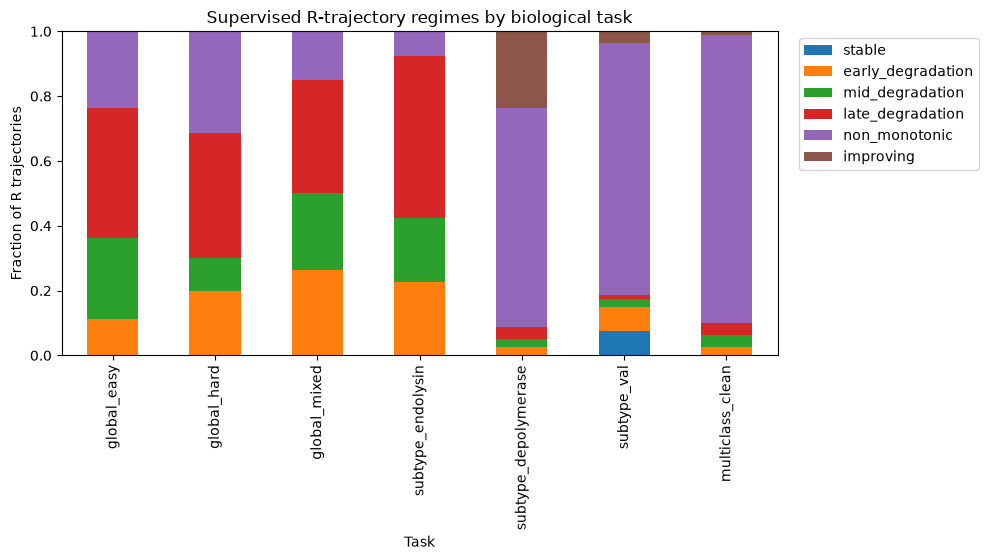

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq20_stepwise_regimes/figures/rq20_supervised_R_regimes_by_task.png


In [14]:

# Figure 2 — supervised regime composition by task for R trajectories.
sup_R_task = sup_task_regimes[sup_task_regimes["axis"].eq("R")].copy()
regime_order = [
    "stable",
    "early_degradation",
    "mid_degradation",
    "late_degradation",
    "non_monotonic",
    "improving",
]

pivot = (
    sup_R_task.pivot_table(
        index="task",
        columns="regime",
        values="fraction",
        fill_value=0,
    )
    .reindex(index=[t for t in TASK_ORDER if t in sup_R_task["task"].unique()])
    .reindex(columns=regime_order, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10.0, 5.7))
pivot.plot(kind="bar", stacked=True, ax=ax)
ax.set_ylabel("Fraction of R trajectories")
ax.set_xlabel("Task")
ax.set_title("Supervised R-trajectory regimes by biological task")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()

path = FIG_DIR / "rq20_supervised_R_regimes_by_task.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", path)


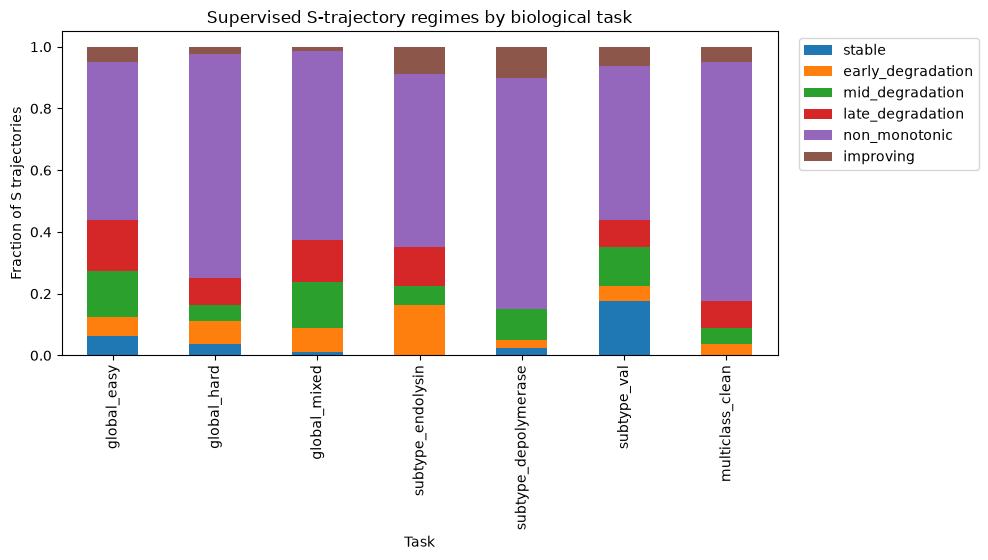

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq20_stepwise_regimes/figures/rq20_supervised_S_regimes_by_task.png


In [15]:

# Figure 3 — supervised regime composition by task for S trajectories.
sup_S_task = sup_task_regimes[sup_task_regimes["axis"].eq("S")].copy()

pivot = (
    sup_S_task.pivot_table(
        index="task",
        columns="regime",
        values="fraction",
        fill_value=0,
    )
    .reindex(index=[t for t in TASK_ORDER if t in sup_S_task["task"].unique()])
    .reindex(columns=regime_order, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10.0, 5.7))
pivot.plot(kind="bar", stacked=True, ax=ax)
ax.set_ylabel("Fraction of S trajectories")
ax.set_xlabel("Task")
ax.set_title("Supervised S-trajectory regimes by biological task")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()

path = FIG_DIR / "rq20_supervised_S_regimes_by_task.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", path)


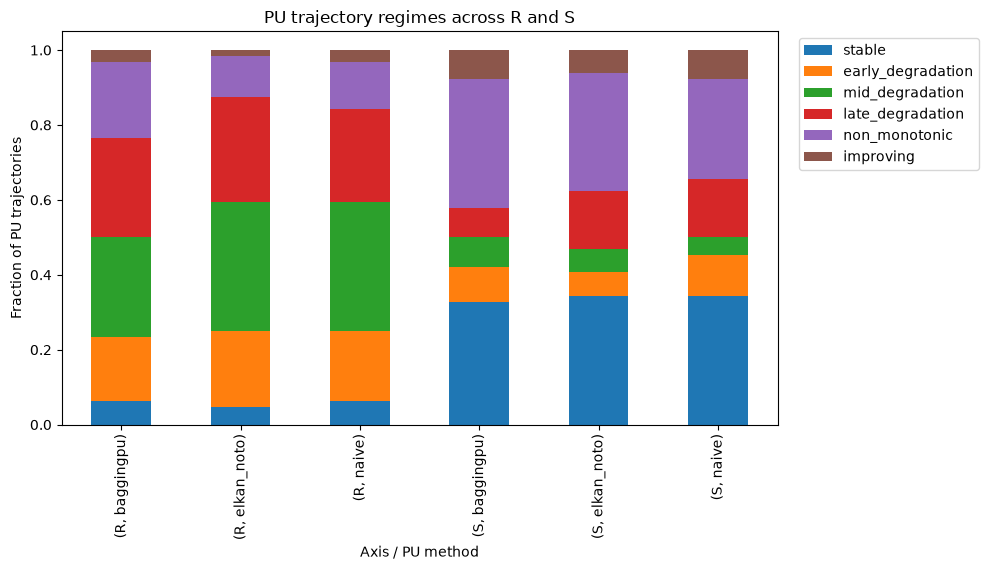

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq20_stepwise_regimes/figures/rq20_PU_regimes_by_method.png


In [16]:

# Figure 4 — PU regime composition by axis and method.
pu_method_plot = (
    pu_method_regimes.pivot_table(
        index=["axis", "method"],
        columns="regime",
        values="fraction",
        fill_value=0,
    )
    .reindex(columns=regime_order, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10.0, 5.8))
pu_method_plot.plot(kind="bar", stacked=True, ax=ax)
ax.set_ylabel("Fraction of PU trajectories")
ax.set_xlabel("Axis / PU method")
ax.set_title("PU trajectory regimes across R and S")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()

path = FIG_DIR / "rq20_PU_regimes_by_method.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", path)


## 13. Compact synthesis tables

In [17]:

def dominant_global_step(summary, axis):
    g = summary[summary["axis"].eq(axis)].copy()
    # Most negative median step = strongest typical degradation.
    row = g.sort_values("median_delta", ascending=True).iloc[0]
    return row["step"], float(row["median_delta"])

sup_R_dom_step, sup_R_dom_delta = dominant_global_step(sup_step_summary, "R")
sup_S_dom_step, sup_S_dom_delta = dominant_global_step(sup_step_summary, "S")
pu_R_dom_step, pu_R_dom_delta = dominant_global_step(pu_step_summary, "R")
pu_S_dom_step, pu_S_dom_delta = dominant_global_step(pu_step_summary, "S")

global_summary = pd.DataFrame([
    {
        "domain": "supervised",
        "metric": SUP_METRIC,
        "R_dominant_global_step": sup_R_dom_step,
        "R_dominant_global_step_median_delta": sup_R_dom_delta,
        "S_dominant_global_step": sup_S_dom_step,
        "S_dominant_global_step_median_delta": sup_S_dom_delta,
        "R_nonmonotonic_fraction": (
            sup_trajectories.query("axis == 'R'")["regime"].eq("non_monotonic").mean()
        ),
        "S_nonmonotonic_fraction": (
            sup_trajectories.query("axis == 'S'")["regime"].eq("non_monotonic").mean()
        ),
        "R_stable_fraction": (
            sup_trajectories.query("axis == 'R'")["regime"].eq("stable").mean()
        ),
        "S_stable_fraction": (
            sup_trajectories.query("axis == 'S'")["regime"].eq("stable").mean()
        ),
    },
    {
        "domain": "PU",
        "metric": PU_METRIC,
        "R_dominant_global_step": pu_R_dom_step,
        "R_dominant_global_step_median_delta": pu_R_dom_delta,
        "S_dominant_global_step": pu_S_dom_step,
        "S_dominant_global_step_median_delta": pu_S_dom_delta,
        "R_nonmonotonic_fraction": (
            pu_trajectories.query("axis == 'R'")["regime"].eq("non_monotonic").mean()
        ),
        "S_nonmonotonic_fraction": (
            pu_trajectories.query("axis == 'S'")["regime"].eq("non_monotonic").mean()
        ),
        "R_stable_fraction": (
            pu_trajectories.query("axis == 'R'")["regime"].eq("stable").mean()
        ),
        "S_stable_fraction": (
            pu_trajectories.query("axis == 'S'")["regime"].eq("stable").mean()
        ),
    },
])

display(global_summary)

print("Supervised R dominant median step:", sup_R_dom_step, sup_R_dom_delta)
print("Supervised S dominant median step:", sup_S_dom_step, sup_S_dom_delta)
print("PU R dominant median step:", pu_R_dom_step, pu_R_dom_delta)
print("PU S dominant median step:", pu_S_dom_step, pu_S_dom_delta)


,domain,metric,R_dominant_global_step,R_dominant_global_step_median_delta,S_dominant_global_step,S_dominant_global_step_median_delta,R_nonmonotonic_fraction,S_nonmonotonic_fraction,R_stable_fraction,S_stable_fraction
0,supervised,mcc,R70→R50,-0.023619,S50→S30,-0.008059,0.444643,0.633929,0.010714,0.044643
1,PU,fraction_P_above_U95,R70→R50,-0.028280,S50→S30,-0.009313,0.145833,0.307292,0.057292,0.338542


Supervised R dominant median step: R70→R50 -0.023618573697472
Supervised S dominant median step: S50→S30 -0.0080591497655514
PU R dominant median step: R70→R50 -0.028280302996569848
PU S dominant median step: S50→S30 -0.0093134323364711



## 14. Scientific interpretation guardrails

After real-data execution, RQ20 should answer:

1. Are the three R transitions approximately similar, or is one interval consistently more damaging?
2. Are S losses concentrated late, as suggested by RQ3/RQ13, or does timing vary substantially by task/model?
3. How common are non-monotonic trajectories?
4. Does ESM2-T30 shift trajectories toward stable or less concentrated degradation regimes?
5. Do learners alter breakpoint timing substantially after representation is fixed?
6. Under PU learning, is R degradation progressive while S remains largely stable/non-monotonic?
7. Is there any evidence for a **universal** breakpoint?

A useful conclusion is allowed to be negative:

> **There is no universal sequence-identity breakpoint at which model generalization collapses. Instead, degradation timing is distributed across early, middle, and late transitions and depends on biological task, representation, and the type of sequence-space constraint.**

That statement should only be used if the executed distributions support it.

### Scope exclusions

RQ20 does **not**:

- analyze diagonal joint R×S trajectories → RQ21;
- explain step timing through sample size or cluster structure → RQ22;
- select deployment models → RQ26;
- optimize ensembles → RQ27.


## 15. Export canonical RQ20 artifacts

In [18]:

exports = {
    "rq20_supervised_stepwise_effects.tsv": sup_steps,
    "rq20_supervised_trajectory_regimes.tsv": sup_trajectories,
    "rq20_supervised_step_summary.tsv": sup_step_summary,
    "rq20_supervised_task_regimes.tsv": sup_task_regimes,
    "rq20_supervised_representation_regimes.tsv": sup_rep_regimes,
    "rq20_supervised_algorithm_regimes.tsv": sup_alg_regimes,
    "rq20_PU_stepwise_effects.tsv": pu_steps,
    "rq20_PU_trajectory_regimes.tsv": pu_trajectories,
    "rq20_PU_step_summary.tsv": pu_step_summary,
    "rq20_PU_task_regimes.tsv": pu_task_regimes,
    "rq20_PU_representation_regimes.tsv": pu_rep_regimes,
    "rq20_PU_method_regimes.tsv": pu_method_regimes,
    "rq20_supervised_breakpoint_timing.tsv": sup_breakpoint,
    "rq20_PU_breakpoint_timing.tsv": pu_breakpoint,
    "rq20_trajectory_complexity_summary.tsv": trajectory_complexity_summary,
    "rq20_global_summary.tsv": global_summary,
}

for filename, df in exports.items():
    path = RQ20_OUT / filename
    df.to_csv(path, sep="\t", index=False)
    print(f"Wrote {filename}: {len(df)} rows")

manifest = {
    "rq": "RQ20",
    "question": "where does degradation occur along 90→70→50→30?",
    "supervised_metric": SUP_METRIC,
    "pu_metric": PU_METRIC,
    "supervised_tolerance": SUP_TOL,
    "pu_tolerance": PU_TOL,
    "supervised_rows": int(len(master)),
    "supervised_surfaces": int(len(coverage)),
    "supervised_R_trajectories": int((sup_trajectories["axis"] == "R").sum()),
    "supervised_S_trajectories": int((sup_trajectories["axis"] == "S").sum()),
    "pu_rows": int(len(pu_native)),
    "pu_surfaces": int(len(pu_surface_coverage)),
    "pu_R_trajectories": int((pu_trajectories["axis"] == "R").sum()),
    "pu_S_trajectories": int((pu_trajectories["axis"] == "S").sum()),
    "training_performed": False,
    "prediction_regeneration_performed": False,
    "bootstrap_performed": False,
    "common_test_recalculation_performed": False,
}

with open(RQ20_OUT / "rq20_manifest.json", "w", encoding="utf-8") as fh:
    json.dump(manifest, fh, indent=2)

print("Wrote rq20_manifest.json")


Wrote rq20_supervised_stepwise_effects.tsv: 3360 rows
Wrote rq20_supervised_trajectory_regimes.tsv: 1120 rows
Wrote rq20_supervised_step_summary.tsv: 6 rows
Wrote rq20_supervised_task_regimes.tsv: 71 rows
Wrote rq20_supervised_representation_regimes.tsv: 45 rows
Wrote rq20_supervised_algorithm_regimes.tsv: 59 rows
Wrote rq20_PU_stepwise_effects.tsv: 1152 rows
Wrote rq20_PU_trajectory_regimes.tsv: 384 rows
Wrote rq20_PU_step_summary.tsv: 6 rows
Wrote rq20_PU_task_regimes.tsv: 24 rows
Wrote rq20_PU_representation_regimes.tsv: 40 rows
Wrote rq20_PU_method_regimes.tsv: 36 rows
Wrote rq20_supervised_breakpoint_timing.tsv: 6 rows
Wrote rq20_PU_breakpoint_timing.tsv: 6 rows
Wrote rq20_trajectory_complexity_summary.tsv: 24 rows
Wrote rq20_global_summary.tsv: 2 rows
Wrote rq20_manifest.json


## 16. Execution gates

In [19]:

required_exports = [
    "rq20_supervised_stepwise_effects.tsv",
    "rq20_supervised_trajectory_regimes.tsv",
    "rq20_supervised_step_summary.tsv",
    "rq20_supervised_task_regimes.tsv",
    "rq20_supervised_representation_regimes.tsv",
    "rq20_supervised_algorithm_regimes.tsv",
    "rq20_PU_stepwise_effects.tsv",
    "rq20_PU_trajectory_regimes.tsv",
    "rq20_PU_step_summary.tsv",
    "rq20_PU_task_regimes.tsv",
    "rq20_PU_representation_regimes.tsv",
    "rq20_PU_method_regimes.tsv",
    "rq20_supervised_breakpoint_timing.tsv",
    "rq20_PU_breakpoint_timing.tsv",
    "rq20_trajectory_complexity_summary.tsv",
    "rq20_global_summary.tsv",
    "rq20_manifest.json",
]

allowed_regimes = {
    "stable",
    "early_degradation",
    "mid_degradation",
    "late_degradation",
    "non_monotonic",
    "improving",
}

assert len(master) == 2240
assert len(coverage) == 140
assert len(sup_steps) == 3360
assert len(sup_trajectories) == 1120
assert (sup_trajectories["axis"].value_counts() == 560).all()
assert set(sup_trajectories["regime"]).issubset(allowed_regimes)

assert len(pu_native) == 768
assert len(pu_surface_coverage) == 48
assert len(pu_steps) == 1152
assert len(pu_trajectories) == 384
assert (pu_trajectories["axis"].value_counts() == 192).all()
assert set(pu_trajectories["regime"]).issubset(allowed_regimes)

# Every trajectory must contain exactly three adjacent deltas and exact telescoping.
for df in [sup_trajectories, pu_trajectories]:
    telescope = (
        df["delta_90_70"]
        + df["delta_70_50"]
        + df["delta_50_30"]
    )
    assert np.allclose(
        telescope.to_numpy(dtype=float),
        df["net_90_30"].to_numpy(dtype=float),
        atol=1e-12,
        rtol=0,
    )

assert all((RQ20_OUT / f).is_file() for f in required_exports)

figure_files = sorted(p.name for p in FIG_DIR.glob("*.png"))
assert len(figure_files) >= 4

print("RQ20_EXECUTION_GATES_OK")
print("Supervised rows:", len(master))
print("Supervised complete surfaces:", len(coverage))
print("Supervised R trajectories:", int((sup_trajectories['axis'] == 'R').sum()))
print("Supervised S trajectories:", int((sup_trajectories['axis'] == 'S').sum()))
print("PU rows:", len(pu_native))
print("PU complete surfaces:", len(pu_surface_coverage))
print("PU R trajectories:", int((pu_trajectories['axis'] == 'R').sum()))
print("PU S trajectories:", int((pu_trajectories['axis'] == 'S').sum()))
print("Exports:", len(required_exports))
print("Figures:", figure_files)
print()
print(
    "Interpretation status: execution gates passed. "
    "Assign REAL-DATA PASS only after the executed notebook and outputs are inspected."
)


RQ20_EXECUTION_GATES_OK
Supervised rows: 2240
Supervised complete surfaces: 140
Supervised R trajectories: 560
Supervised S trajectories: 560
PU rows: 768
PU complete surfaces: 48
PU R trajectories: 192
PU S trajectories: 192
Exports: 17
Figures: ['rq20_PU_regimes_by_method.png', 'rq20_global_stepwise_deltas.png', 'rq20_supervised_R_regimes_by_task.png', 'rq20_supervised_S_regimes_by_task.png']

Interpretation status: execution gates passed. Assign REAL-DATA PASS only after the executed notebook and outputs are inspected.
